# 02 · Exploratory Data Analysis
Input: `data/interim/amazon_us_clean.csv` (output of notebook 01): 1,351 unique products in U.S. USD.

Questions we want the data to answer before we model anything:
1. What do price, discount, rating and review-count distributions look like? Are they skewed, and are there outliers?
2. How does the catalogue break down by U.S. category and brand?
3. How do **price**, **discount** and **rating** relate to **review volume** (our best proxy for sales velocity)?
4. Which variables are correlated or redundant, and what does that mean for feature engineering?

Every figure is also saved to `reports/figures/` for the web app and reports.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.ticker as mtick, seaborn as sns
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)

# One consistent, colour-blind-checked palette for every chart (fixed order: colour follows the entity)
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
SEQ = sns.blend_palette(["#cde2fb", "#2a78d6", "#0d366b"], as_cmap=True)
DIV = sns.blend_palette(["#2a78d6", "#f0efec", "#e34948"], as_cmap=True)
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e6e5e0"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.titlecolor": INK, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.titlelocation": "left", "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.prop_cycle": plt.cycler(color=SERIES),
    "lines.linewidth": 2, "figure.dpi": 110, "font.size": 10, "legend.frameon": False,
})
usd = mtick.StrMethodFormatter("${x:,.0f}")
import matplotlib.dates as mdates
def fmt_dates(ax):
    loc = mdates.AutoDateLocator(minticks=3, maxticks=8); ax.xaxis.set_major_locator(loc); ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(loc))
def savefig(fig, name): fig.savefig(FIG / f"{name}.png", bbox_inches="tight")

In [2]:
df = pd.read_csv(ROOT / "data/interim/amazon_us_clean.csv")
print(df.shape)
df.describe().T.round(2)

(1351, 23)


,count,mean,std,min,25%,50%,75%,max
cat_depth,1351.0,4.28,0.78,2.00,4.00,4.00,5.00,7.00
price_usd,1351.0,68.67,130.59,5.99,9.99,22.99,52.99,1251.99
list_price_usd,1351.0,111.74,199.25,5.99,19.99,41.99,93.99,2244.99
discount_pct,1351.0,41.91,18.23,0.00,28.44,46.74,60.00,61.15
discount_usd,1351.0,43.07,77.95,0.00,9.00,17.00,42.00,993.00
orig_discount_pct,1351.0,44.46,21.45,0.00,28.44,46.74,60.03,94.01
rating,1351.0,4.09,0.30,2.00,3.90,4.10,4.30,5.00
rating_count,1351.0,17619.05,42119.63,2.00,1094.50,4736.00,15995.00,426973.00
review_sentiment,1351.0,0.87,0.24,-0.50,0.75,1.00,1.00,1.00
n_reviews_sampled,1351.0,7.85,0.85,1.00,8.00,8.00,8.00,9.00


## 1. Univariate distributions

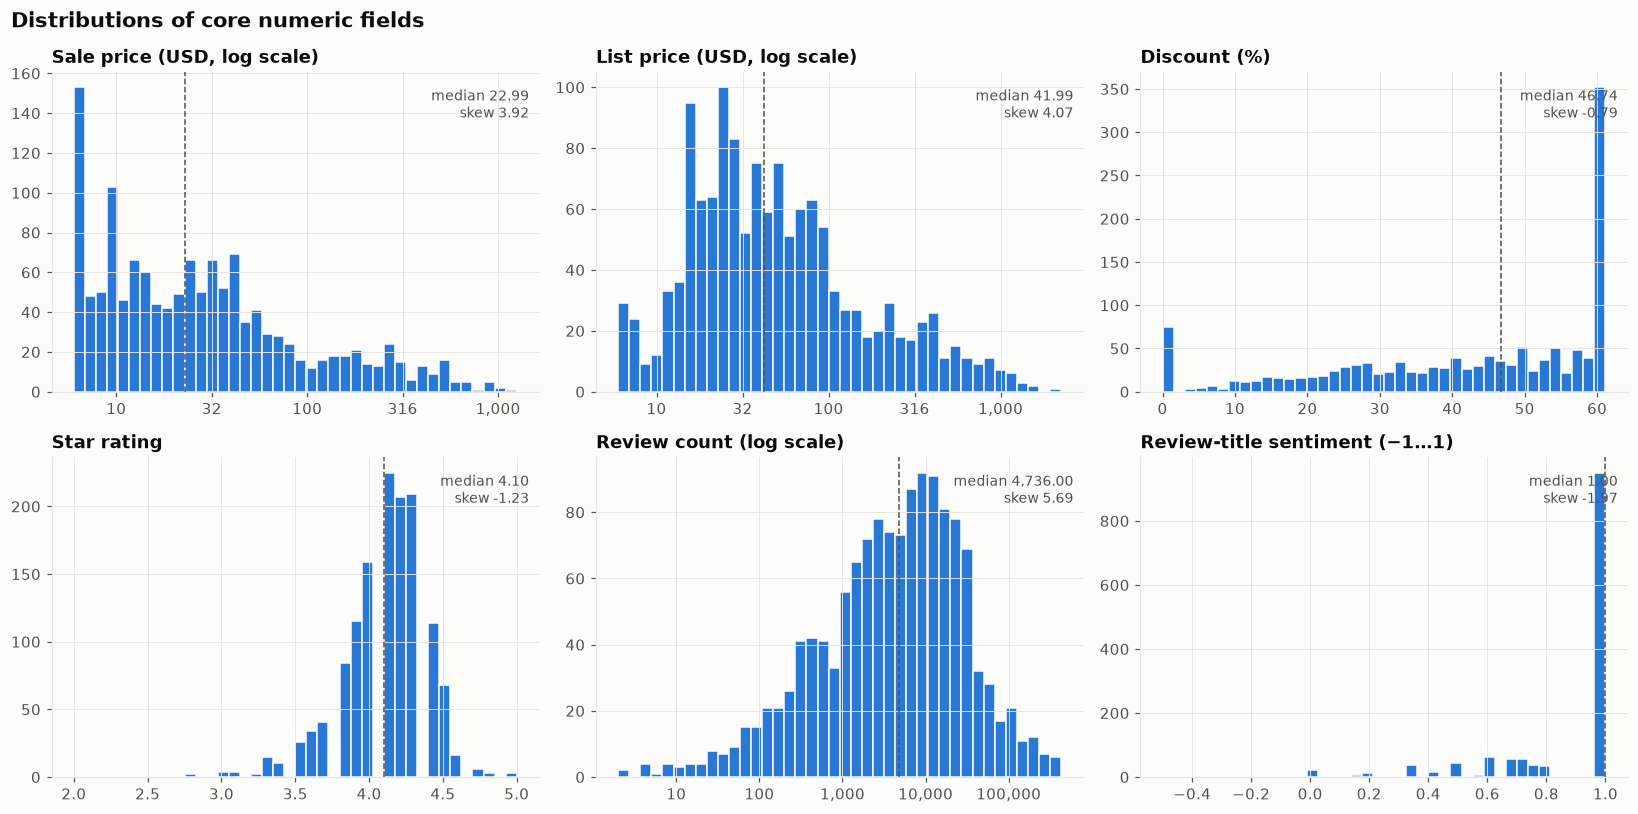

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
specs = [("price_usd", "Sale price (USD, log scale)", True), ("list_price_usd", "List price (USD, log scale)", True),
         ("discount_pct", "Discount (%)", False), ("rating", "Star rating", False),
         ("rating_count", "Review count (log scale)", True), ("review_sentiment", "Review-title sentiment (−1…1)", False)]
for ax, (col, title, log) in zip(axes.flat, specs):
    data = np.log10(df[col]) if log else df[col]
    ax.hist(data, bins=40, color=SERIES[0], edgecolor="#fcfcfb", linewidth=1)
    ax.axvline(data.median(), color=INK2, ls="--", lw=1)
    ax.set_title(title)
    if log:
        ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{10**v:,.0f}"))
    ax.text(0.98, 0.95, f"median {df[col].median():,.2f}\nskew {df[col].skew():.2f}", transform=ax.transAxes,
            ha="right", va="top", color=INK2, fontsize=9)
fig.suptitle("Distributions of core numeric fields", x=0.01, ha="left", fontweight="bold", fontsize=14)
fig.tight_layout(); savefig(fig, "02_univariate")

**Reading the distributions**
- **Price and review count are heavily right-skewed** (skew > 4). Model them on a **log scale** (`log1p`), otherwise a few $1,000+ TVs and 400k-review cables dominate the loss.
- **Ratings sit in a narrow 3.8–4.5 band** (Amazon's well-known positivity bias), so small rating differences carry signal.
- **Discount** is spread out, with a spike at the ~60% cap introduced in cleaning (U.S. reference-price realism).
- Sentiment is mostly positive, which matches the rating distribution.

### 1.1 Outlier analysis (IQR on log scale)

In [4]:
def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)

out = pd.DataFrame({
    "raw_scale": {c: iqr_outliers(df[c]).sum() for c in ["price_usd", "rating_count", "discount_pct", "rating"]},
    "log_scale": {c: iqr_outliers(np.log1p(df[c])).sum() for c in ["price_usd", "rating_count", "discount_pct", "rating"]},
})
out

,raw_scale,log_scale
price_usd,198,17
rating_count,130,18
discount_pct,0,92
rating,19,34


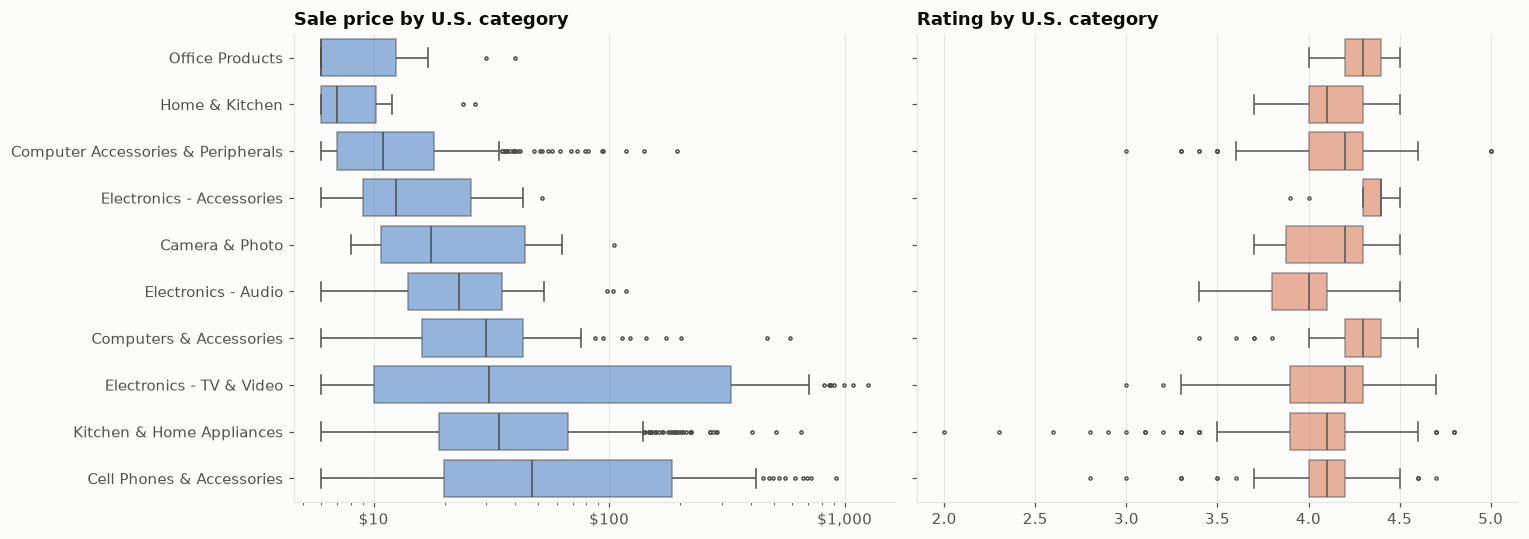

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
order = df.groupby("us_category").price_usd.median().sort_values().index
top = df.us_category.value_counts().loc[lambda s: s >= 10].index
order = [c for c in order if c in top]
sns.boxplot(data=df[df.us_category.isin(top)], y="us_category", x="price_usd", order=order, ax=axes[0],
            color=SERIES[0], fliersize=2, linewidth=1, boxprops=dict(alpha=.55))
axes[0].set_xscale("log"); axes[0].xaxis.set_major_formatter(usd); axes[0].set(title="Sale price by U.S. category", xlabel="", ylabel="")
sns.boxplot(data=df[df.us_category.isin(top)], y="us_category", x="rating", order=order, ax=axes[1],
            color=SERIES[1], fliersize=2, linewidth=1, boxprops=dict(alpha=.55))
axes[1].set(title="Rating by U.S. category", xlabel="", ylabel=""); axes[1].set_yticklabels([])
fig.tight_layout(); savefig(fig, "02_category_boxplots")

**Outlier decision.** Outliers on the raw scale are **real products** (TVs, phones, best-selling cables), not data errors, so we **keep them**.
On the log scale almost none are left. The treatment is: log-transform skewed features, and use robust or tree models.
Low-rating outliers (< 3.0) are rare but matter for the business: they mark poorly performing listings that investors should avoid.

## 2. Catalogue composition

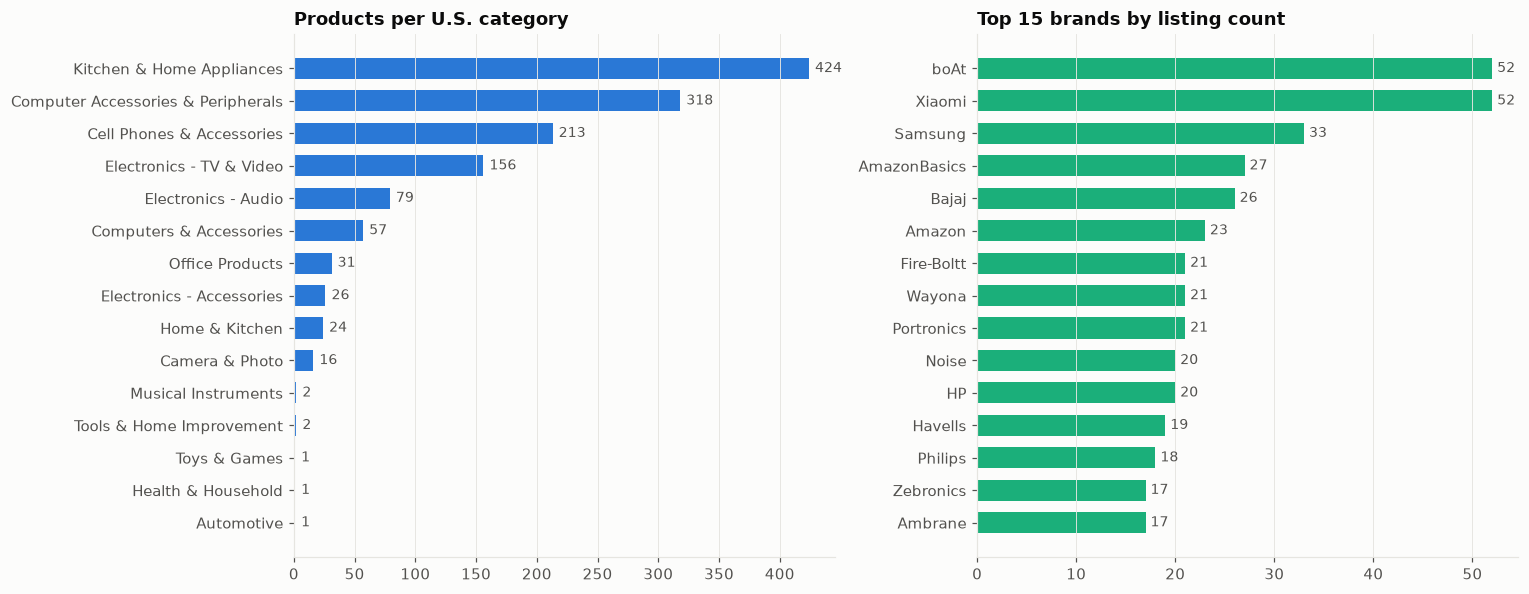

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
vc = df.us_category.value_counts()
axes[0].barh(vc.index[::-1], vc.values[::-1], color=SERIES[0], height=0.65)
for y, v in enumerate(vc.values[::-1]): axes[0].text(v + 5, y, f"{v}", va="center", color=INK2, fontsize=9)
axes[0].set(title="Products per U.S. category"); axes[0].grid(axis="y", visible=False)

brands = df.brand.value_counts().head(15)
axes[1].barh(brands.index[::-1], brands.values[::-1], color=SERIES[2], height=0.65)
for y, v in enumerate(brands.values[::-1]): axes[1].text(v + .5, y, f"{v}", va="center", color=INK2, fontsize=9)
axes[1].set(title="Top 15 brands by listing count"); axes[1].grid(axis="y", visible=False)
fig.tight_layout(); savefig(fig, "02_composition")

Five U.S. categories cover > 85% of the catalogue: *Kitchen & Home Appliances*, *Computer Accessories*, *Cell Phones & Accessories*, *TV & Video* and *Audio*.
Long-tail categories (Toys, Automotive, Health, …) have 1–2 products each, so in modelling they get grouped as **"Other"** to avoid unstable estimates.

## 3. Bivariate: what drives review volume (sales proxy)?

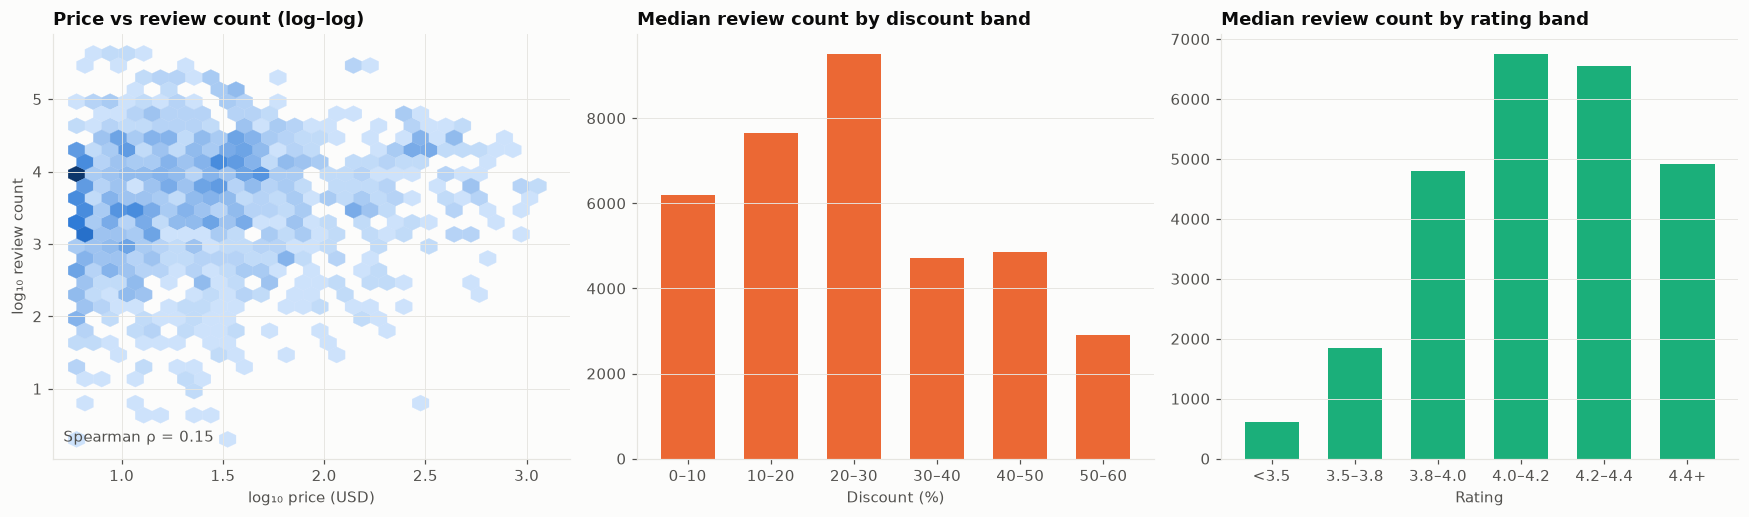

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
x = np.log10(df.price_usd); y = np.log10(df.rating_count)
axes[0].hexbin(x, y, gridsize=28, cmap=SEQ, mincnt=1, linewidths=0.2)
axes[0].set(title="Price vs review count (log–log)", xlabel="log₁₀ price (USD)", ylabel="log₁₀ review count")
axes[0].text(.02, .04, f"Spearman ρ = {df.price_usd.corr(df.rating_count, method='spearman'):.2f}", transform=axes[0].transAxes, color=INK2)

bins = pd.cut(df.discount_pct, [-.1, 10, 20, 30, 40, 50, 62], labels=["0–10", "10–20", "20–30", "30–40", "40–50", "50–60"])
g = df.groupby(bins, observed=True).rating_count.median()
axes[1].bar(g.index.astype(str), g.values, color=SERIES[1], width=.65)
axes[1].set(title="Median review count by discount band", xlabel="Discount (%)"); axes[1].grid(axis="x", visible=False)

rb = pd.cut(df.rating, [0, 3.5, 3.8, 4.0, 4.2, 4.4, 5], labels=["<3.5", "3.5–3.8", "3.8–4.0", "4.0–4.2", "4.2–4.4", "4.4+"])
g2 = df.groupby(rb, observed=True).rating_count.median()
axes[2].bar(g2.index.astype(str), g2.values, color=SERIES[2], width=.65)
axes[2].set(title="Median review count by rating band", xlabel="Rating"); axes[2].grid(axis="x", visible=False)
fig.tight_layout(); savefig(fig, "02_drivers")

**Business reading** (what the data actually shows)
- **Price vs volume:** a *weak positive* rank correlation (ρ ≈ 0.15). This is **selection bias**, not a reverse demand curve: the scrape only covers listings that rank on search pages, and expensive items only reach those pages when they come from strong brands with large review bases.
  → Cross-sectional data **can't identify true price elasticity**. For the demand simulation we use **published U.S. e-commerce elasticity ranges** (≈ −0.8 to −2.0 by category), not these slopes.
- **Discount:** volume peaks at a **20–30% discount** and *falls* for deeper cuts. Very deep discounts usually mean inflated reference prices on weaker products. Deep discounting isn't a growth strategy by itself.
- **Rating:** volume climbs steeply up to **4.0–4.4★**. Products under 3.8★ rarely scale. The 4.4+ band dips because perfect ratings are mostly **new listings with few reviews**. This rating threshold is a key investor signal.

### 3.1 Category-level economics snapshot

In [8]:
cat = (df.assign(us_category=np.where(df.us_category.isin(top), df.us_category, "Other"))
        .groupby("us_category")
        .agg(products=("product_id", "count"), median_price=("price_usd", "median"),
             median_discount=("discount_pct", "median"), avg_rating=("rating", "mean"),
             median_reviews=("rating_count", "median"), total_reviews=("rating_count", "sum"))
        .sort_values("total_reviews", ascending=False))
cat["review_share_pct"] = (cat.total_reviews / cat.total_reviews.sum() * 100).round(1)
cat.round(2)

,products,median_price,median_discount,avg_rating,median_reviews,total_reviews,review_share_pct
us_category,,,,,,,
Cell Phones & Accessories,213,46.99,49.60,4.09,14185.0,5518036,23.2
Electronics - Audio,79,22.99,60.01,3.95,28324.0,4842110,20.3
Computer Accessories & Peripherals,318,10.99,54.38,4.14,5659.0,3819555,16.0
Kitchen & Home Appliances,424,33.99,40.50,4.04,2281.5,2603527,10.9
Computers & Accessories,57,29.99,46.58,4.24,22420.0,2516495,10.6
Electronics - TV & Video,156,30.99,49.92,4.07,1532.5,2371410,10.0
Electronics - Accessories,26,12.49,19.39,4.36,26878.5,1154228,4.8
Home & Kitchen,24,6.99,25.31,4.12,5208.0,387542,1.6
Camera & Photo,16,17.49,50.86,4.12,11865.5,322657,1.4


## 4. Correlation structure

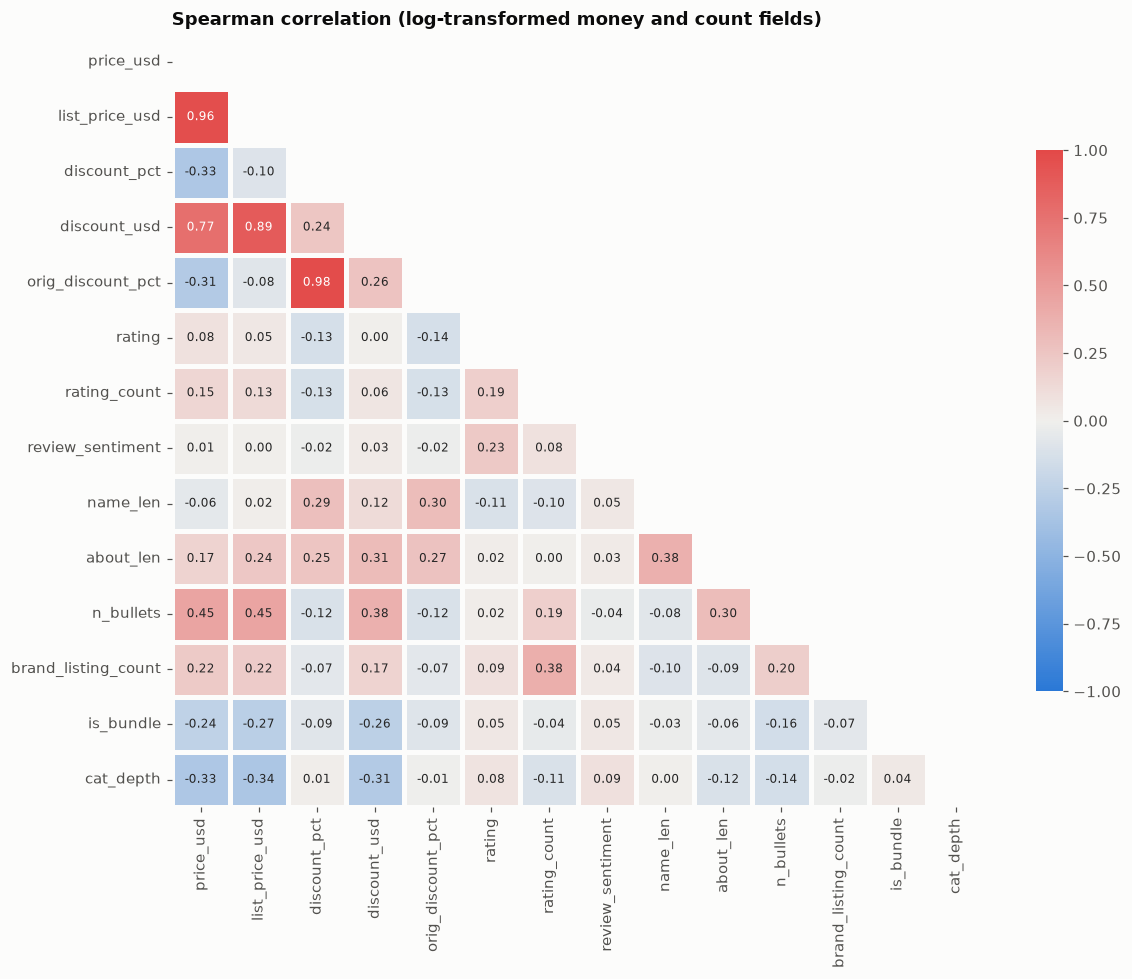

In [9]:
num = ["price_usd", "list_price_usd", "discount_pct", "discount_usd", "orig_discount_pct", "rating", "rating_count",
       "review_sentiment", "name_len", "about_len", "n_bullets", "brand_listing_count", "is_bundle", "cat_depth"]
corr = df[num].assign(price_usd=np.log1p(df.price_usd), list_price_usd=np.log1p(df.list_price_usd),
                      rating_count=np.log1p(df.rating_count), discount_usd=np.log1p(df.discount_usd)).corr(method="spearman")
fig, ax = plt.subplots(figsize=(11, 9))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap=DIV, vmin=-1, vmax=1, center=0, annot=True, fmt=".2f", annot_kws={"size": 8},
            linewidths=2, linecolor="#fcfcfb", cbar_kws={"shrink": .7}, ax=ax)
ax.set_title("Spearman correlation (log-transformed money and count fields)"); ax.grid(False)
fig.tight_layout(); savefig(fig, "02_correlation")

In [10]:
pairs = (corr.where(~mask).stack().rename("rho").reset_index()
         .assign(abs_rho=lambda d: d.rho.abs()).sort_values("abs_rho", ascending=False))
pairs.head(8)

,level_0,level_1,rho,abs_rho
58,orig_discount_pct,discount_pct,0.983849,0.983849
14,list_price_usd,price_usd,0.964732,0.964732
43,discount_usd,list_price_usd,0.890312,0.890312
42,discount_usd,price_usd,0.766284,0.766284
140,n_bullets,price_usd,0.452440,0.452440
141,n_bullets,list_price_usd,0.446700,0.446700
160,brand_listing_count,rating_count,0.384426,0.384426
134,about_len,name_len,0.378441,0.378441


**Multicollinearity decisions**
- `price_usd` and `list_price_usd` are almost collinear (ρ ≈ 0.95). Keep `price_usd` plus `discount_pct`; derive list price when needed.
- `discount_pct` ↔ `orig_discount_pct` are redundant. Keep `orig_discount_pct` only as a "deep-discount listing" flag.
- `discount_usd` is mostly price × discount, so drop it as a model feature.
- Content features (`about_len`, `n_bullets`, `name_len`) correlate with each other, so we keep a **listing-quality score** instead (built in notebook 03).

## 5. Price elasticity view by category

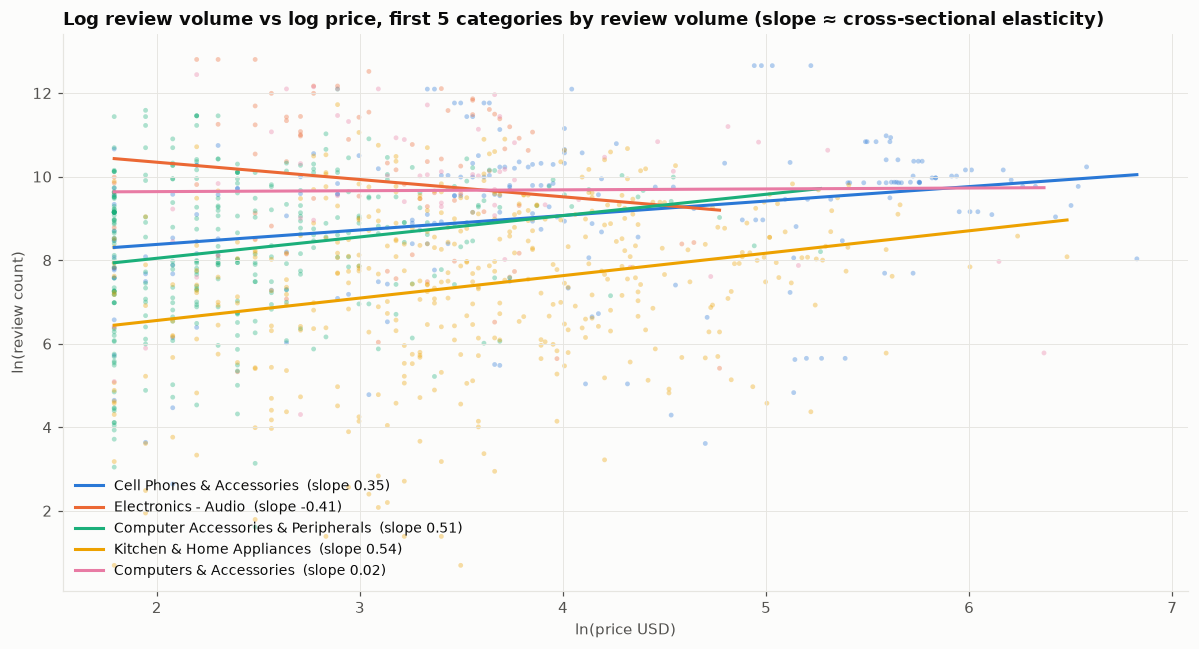

In [11]:
fig, ax = plt.subplots(figsize=(11, 6))
cats = list(cat.index[:5])
for i, c in enumerate(cats):
    d = df[df.us_category == c]
    xs, ys = np.log(d.price_usd), np.log(d.rating_count)
    b, a = np.polyfit(xs, ys, 1)
    ax.scatter(xs, ys, s=10, color=SERIES[i], alpha=.35, edgecolor="none")
    gx = np.linspace(xs.min(), xs.max(), 20)
    ax.plot(gx, a + b * gx, color=SERIES[i], label=f"{c}  (slope {b:.2f})")
ax.set(title="Log review volume vs log price, first 5 categories by review volume (slope ≈ cross-sectional elasticity)",
       xlabel="ln(price USD)", ylabel="ln(review count)")
ax.legend(loc="lower left", fontsize=9)
fig.tight_layout(); savefig(fig, "02_elasticity")

The fitted slopes are mixed in sign (−0.4 to +0.5). This confirms the point above: **cross-sectional slopes are confounded by brand strength and listing age**, so they aren't causal elasticities.
Notebook 03 therefore uses industry-standard elasticities per category, applied to **within-product price changes over time** (promotions), which is where elasticity really operates.

## 6. EDA takeaways → feature-engineering plan
| Finding | Action in notebook 03 |
|---|---|
| Price and reviews are log-normal | Log features and log targets; tree models |
| Review count ∝ cumulative units sold | Derive lifetime units = reviews ÷ U.S. review rate (≈1–2%) |
| Rating threshold ~4.0–4.4★ | Rating-quality multiplier on demand; `rating_band` feature |
| Category drives price level; cross-sectional elasticity is confounded | Category-specific fees, COGS, return rates; literature elasticities for promo months |
| Long-tail categories | Group as "Other" |
| No time dimension in the data | Approximate launch date from ASIN sequence; build a monthly panel with U.S. seasonality (Prime Day, BFCM, Q4) |